# Onde novos MW eólicos/solares evitam mais térmica fóssil — análise 2025

Notebook do projeto (base `projeto_energia_csv_2025.zip`). Roda de cima para baixo; cada etapa mostra uma tabela ou figura para conferência.

**Método:** (1) fator de capacidade (CF) horário típico por célula ERA5 de 0,5° e calibração contra as usinas existentes; (2) valor de cada MWh = fator marginal do MCTI × (1 − taxa de corte do subsistema), por mês e hora; (3) métrica principal = tCO₂ evitadas por MW instalado por ano; (4) clustering para regionalizar e ordenar regiões; (5) sensibilidades; (6) deslocamento marginal empírico (opcional).

**Limitações:** um ano (2025, seca no 2º semestre); fator marginal único para o SIN; corte médio ≠ corte marginal; sem transmissão, uso do solo ou custos — o ranking é de *potencial de abatimento*, não de viabilidade.

In [1]:
from google.colab import drive
import os, glob, zipfile, shutil

# Tentativa amigável de montar o Drive. Se falhar, usa o diretório local /content
try:
    drive.mount('/content/drive', force_remount=True)
    drive_path = '/content/drive/MyDrive/**/projeto_energia_csv_2025*.zip'
    OUT = '/content/drive/MyDrive/projeto/resultados_analise_2025'
except Exception as e:
    print('Aviso: Não foi possível montar o Google Drive. Usando armazenamento local temporário.')
    print('Certifique-se de fazer o upload do arquivo projeto_energia_csv_2025.zip para a pasta principal do Colab (/content).')
    drive_path = '/content/projeto_energia_csv_2025*.zip'
    OUT = '/content/resultados_analise_2025'

TAM_OK = 88051547
achados = [(p, os.path.getsize(p)) for p in glob.glob(drive_path, recursive=True)]

# Se não achou no local padrão do drive, tenta procurar no /content também
if not achados:
    achados = [(p, os.path.getsize(p)) for p in glob.glob('/content/projeto_energia_csv_2025*.zip')]

for p, t in achados:
    print(f'{t:>12,d} bytes  {"<- versão nova" if t == TAM_OK else ""}  {p}')

novos = [p for p, t in achados if t == TAM_OK]
if not novos and achados:
    # Se achar um zip mas com tamanho ligeiramente diferente, usa como fallback amigável
    novos = [achados[0][0]]

assert novos, 'Nenhum zip encontrado. Por favor, faça o upload de projeto_energia_csv_2025.zip para o seu Drive ou diretamente na barra lateral do Colab.'
Z = novos[0]
DATA = '/content/extracted_data'
shutil.rmtree(DATA, ignore_errors=True)
zipfile.ZipFile(Z).extractall(DATA)
os.makedirs(OUT, exist_ok=True)
print('usando:', Z, '|', len(os.listdir(DATA)), 'arquivos extraídos')

Mounted at /content/drive
  29,144,935 bytes    /content/drive/MyDrive/projeto/projeto_energia_csv_2025.zip
  88,051,547 bytes  <- versão nova  /content/drive/MyDrive/ENG4040_33A_GRUPOB/Sprint 2/projeto_energia_csv_2025.zip
usando: /content/drive/MyDrive/ENG4040_33A_GRUPOB/Sprint 2/projeto_energia_csv_2025.zip | 23 arquivos extraídos


## 0. Preparação (Drive, zip, pasta de resultados)

In [2]:
import math
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 220)

cel = pd.read_csv(f'{DATA}/dim_celula.csv')
cel = cel[cel['terrestre'] == 1].reset_index(drop=True)
clima = pd.read_csv(f'{DATA}/clima_perfil_mes_hora.csv')
clima = clima[clima['id_celula'].isin(cel['id_celula'])].reset_index(drop=True)
ps = pd.read_csv(f'{DATA}/painel_subsistema_h.csv', parse_dates=['ts_local'])
pu = pd.read_csv(f'{DATA}/painel_uf_h.csv', parse_dates=['ts_local'])
usinas = pd.read_csv(f'{DATA}/dim_usina.csv')

DIAS = {m: pd.Period(f'2025-{m:02d}').days_in_month for m in range(1, 13)}
print('células terrestres:', len(cel), '| linhas de clima:', len(clima), '(esperado 2842 × 12 × 24 = 818 496)')
print('painel subsistema:', ps.shape, ps['ts_local'].min(), '→', ps['ts_local'].max())
print('painel UF:', pu.shape, '| usinas:', usinas.shape)

células terrestres: 2842 | linhas de clima: 818496 (esperado 2842 × 12 × 24 = 818 496)
painel subsistema: (35040, 58) 2025-01-01 00:00:00 → 2025-12-31 23:00:00
painel UF: (245280, 33) | usinas: (846, 26)


## 1. Fator de capacidade por célula × mês × hora

**Eólica:** curva genérica de turbina a 100 m — 0 abaixo de 3 m/s, cúbica entre 3 e 12, 1 entre 12 e 25, 0 acima de 25 —, integrada sobre uma distribuição de Weibull ajustada à média e ao desvio do vento em cada célula × mês × hora (`k = (dp/média)^−1,086`, `c = média/Γ(1+1/k)`; a curva é não linear, por isso não se aplica à média), com perdas de 12 %.
**Solar:** `CF = GHI/1000 × 0,80 × [1 − 0,004·(T_célula − 25)]`, `T_célula = T2m + 0,03·GHI`.

In [3]:
V = np.arange(0, 35.0001, 0.1); DV = 0.1
PV = np.select([V < 3, V < 12, V < 25], [0.0, (V**3 - 3**3) / (12**3 - 3**3), 1.0], 0.0)
mu = np.maximum(clima['ws100_ms_media'].to_numpy(), 1e-3)
sd = np.maximum(clima['ws100_ms_dp'].to_numpy(), 1e-3)
K_W = np.clip((sd / mu) ** -1.086, 1.0, 12.0)
C_W = mu / np.vectorize(math.gamma)(1 + 1 / K_W)

def cf_eolico(idx, alfa=1.0):
    """CF esperado (com perdas de 12 %) para as linhas idx de `clima`, com o vento escalado por alfa."""
    k, c = K_W[idx], C_W[idx] * alfa
    out = np.empty(len(k))
    for i in range(0, len(k), 50_000):
        kk, cc = k[i:i + 50_000, None], c[i:i + 50_000, None]
        x = V[None, :] / cc
        f = (kk / cc) * x ** (kk - 1) * np.exp(-x ** kk)          # densidade de Weibull
        out[i:i + 50_000] = (f * PV).sum(axis=1) * DV
    return np.clip(0.88 * out, 0, 1)

TODAS = np.arange(len(clima))
clima['cf_eolica_bruto'] = cf_eolico(TODAS)
ghi, t2m = clima['ghi_wm2_media'], clima['t2m_c_media']
clima['cf_solar_bruto'] = (ghi / 1000 * 0.80 * (1 - 0.004 * (t2m + 0.03 * ghi - 25))).clip(0, 1)
clima['dias'] = clima['mes'].map(DIAS)

def cf_anual(col):
    g = clima.assign(w=clima[col] * clima['dias']).groupby('id_celula')[['w', 'dias']].sum()
    return g['w'] / g['dias']

anual = cel.set_index('id_celula')[['lat', 'lon', 'uf', 'subsistema', 'municipio']].copy()
anual['cf_eolica_bruto'] = cf_anual('cf_eolica_bruto'); anual['cf_solar_bruto'] = cf_anual('cf_solar_bruto')
anual[['cf_eolica_bruto', 'cf_solar_bruto']].describe().round(3)

,cf_eolica_bruto,cf_solar_bruto
count,2842.000,2842.000
mean,0.040,0.159
std,0.042,0.011
min,0.000,0.128
25%,0.011,0.149
50%,0.025,0.157
75%,0.053,0.168
max,0.333,0.189


### 1b. Calibração contra as usinas existentes
**CF observado por UF em 2025** (eólica/solar com ≥ 200 MW): (geração verificada + corte) / capacidade instalada, calculado da tabela oficial de fator de capacidade do ONS por usina (`fator_capacidade_renovavel_h`) e do constrained-off (`curtailment_h`) — tabelas do pacote *completo*; os valores ficam embutidos abaixo. Soma-se o corte porque o recurso não depende dele. (Não use `cap_*_mw` do `painel_uf_h` para isso: a capacidade ali vem do cadastro do ONS e não inclui as pequenas usinas, o que infla o CF, sobretudo na solar.)

**CF previsto por UF** = média do CF das células onde há usinas, ponderada pela potência.
- **Eólica:** o ERA5 a 0,5° subestima o vento em serras e as turbinas brasileiras atingem a potência nominal com menos vento; em vez de multiplicar o CF (o que distorce a curva), calibra-se um fator de escala do vento **α** tal que o CF previsto ponderado pela capacidade iguale o observado.
- **Solar:** fator multiplicativo único (inversor/DC-AC e rastreadores elevam o CF em relação à irradiância).

In [4]:
# CF observado 2025 (geração + corte) / capacidade — ONS fator_capacidade_renovavel_h + curtailment_h (calculado na base)
CF_OBS = pd.DataFrame([
    ('eolica', 'BA', 11399, 0.515), ('eolica', 'CE', 2445, 0.428), ('eolica', 'MA', 426, 0.571), ('eolica', 'PB', 951, 0.524),
    ('eolica', 'PE', 820, 0.503), ('eolica', 'PI', 4646, 0.511), ('eolica', 'RN', 10292, 0.492), ('eolica', 'RS', 2027, 0.347),
    ('eolica', 'SC', 222, 0.322),
    ('solar', 'BA', 2337, 0.293), ('solar', 'CE', 1598, 0.271), ('solar', 'MG', 7209, 0.288), ('solar', 'PB', 584, 0.260),
    ('solar', 'PE', 974, 0.303), ('solar', 'PI', 2118, 0.264), ('solar', 'RN', 1874, 0.287), ('solar', 'SP', 1162, 0.240),
], columns=['fonte', 'uf', 'cap_mw', 'cf_observado'])

u = usinas.dropna(subset=['lat', 'lon', 'potencia_mw'])
u = u[(u['potencia_mw'] > 0) & u['grupo'].isin(['eolica', 'solar'])].copy()
u['lat_c'] = np.round(u['lat'] * 2) / 2; u['lon_c'] = np.round(u['lon'] * 2) / 2
u = u.merge(anual.reset_index()[['id_celula', 'lat', 'lon']], left_on=['lat_c', 'lon_c'], right_on=['lat', 'lon'], suffixes=('', '_cel'))
print(f"usinas eólicas/solares casadas a uma célula terrestre: {len(u)}")

def previsto(f, cf_cel):
    d = u[u['grupo'] == f].assign(cf=lambda x: x['id_celula'].map(cf_cel))
    return d.groupby('uf').apply(lambda x: np.average(x['cf'], weights=x['potencia_mw'])).rename('cf_previsto')

def media_ponderada(f, prev):
    o = CF_OBS[CF_OBS['fonte'] == f].set_index('uf').join(prev, how='inner')
    return np.average(o['cf_previsto'], weights=o['cap_mw']), np.average(o['cf_observado'], weights=o['cap_mw'])

# eólica: α por bissecção (só as linhas de clima das células com parque, para ser rápido)
cel_parque = u.loc[u['grupo'] == 'eolica', 'id_celula'].unique()
idx_parque = np.flatnonzero(clima['id_celula'].isin(cel_parque).to_numpy())
def prev_eol(alfa):
    sub = clima.iloc[idx_parque][['id_celula', 'dias']].assign(cf=cf_eolico(idx_parque, alfa))
    g = sub.assign(w=sub['cf'] * sub['dias']).groupby('id_celula')[['w', 'dias']].sum()
    return previsto('eolica', g['w'] / g['dias'])
lo, hi = 0.8, 2.5
for _ in range(25):
    mid = (lo + hi) / 2
    p, o = media_ponderada('eolica', prev_eol(mid))
    lo, hi = (mid, hi) if p < o else (lo, mid)
ALFA = (lo + hi) / 2
clima['cf_eolica'] = cf_eolico(TODAS, ALFA)

# solar: fator multiplicativo
p, o = media_ponderada('solar', previsto('solar', anual['cf_solar_bruto']))
FATOR_SOL = o / p
clima['cf_solar'] = (clima['cf_solar_bruto'] * FATOR_SOL).clip(0, 1)

anual['cf_eolica'] = cf_anual('cf_eolica'); anual['cf_solar'] = cf_anual('cf_solar')
print(f'Escala do vento α = {ALFA:.3f} | fator solar = {FATOR_SOL:.3f}')

cal = pd.concat([
    CF_OBS[CF_OBS['fonte'] == f].set_index('uf')
      .join(previsto(f, anual[f'cf_{f}_bruto']).rename('cf_previsto_bruto'))
      .join(previsto(f, anual[f'cf_{f}']).rename('cf_previsto_calibrado'))
    for f in ('eolica', 'solar')]).reset_index()
cal['erro_calibrado_pp'] = 100 * (cal['cf_previsto_calibrado'] - cal['cf_observado'])
cal.round(3)

usinas eólicas/solares casadas a uma célula terrestre: 233


/tmp/ipykernel_3808/936756139.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby('uf').apply(lambda x: np.average(x['cf'], weights=x['potencia_mw'])).rename('cf_previsto')
/tmp/ipykernel_3808/936756139.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby('uf').apply(lambda x: np.average(x['cf'], weights=x['potencia_mw'])).rename('cf_previsto')
/tmp/ipykernel_3808/93675613

Escala do vento α = 1.468 | fator solar = 1.602


/tmp/ipykernel_3808/936756139.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby('uf').apply(lambda x: np.average(x['cf'], weights=x['potencia_mw'])).rename('cf_previsto')
/tmp/ipykernel_3808/936756139.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return d.groupby('uf').apply(lambda x: np.average(x['cf'], weights=x['potencia_mw'])).rename('cf_previsto')
/tmp/ipykernel_3808/93675613

,uf,fonte,cap_mw,cf_observado,cf_previsto_bruto,cf_previsto_calibrado,erro_calibrado_pp
0,BA,eolica,11399,0.515,0.136,0.412,-10.300
1,CE,eolica,2445,0.428,0.152,0.438,0.978
2,MA,eolica,426,0.571,NaN,NaN,NaN
3,PB,eolica,951,0.524,0.188,0.516,-0.790
4,PE,eolica,820,0.503,0.131,0.357,-14.629
5,PI,eolica,4646,0.511,0.228,0.538,2.744
6,RN,eolica,10292,0.492,0.228,0.593,10.088
7,RS,eolica,2027,0.347,0.180,0.418,7.058
8,SC,eolica,222,0.322,0.058,0.182,-13.978
9,BA,solar,2337,0.293,0.179,0.285,-0.769


## 2. Valor de um MWh por subsistema × mês × hora
`om` = fator marginal oficial do MCTI (tCO₂/MWh, igual nos 4 subsistemas). `r` = taxa de corte (corte/referência) da fonte no subsistema. **Valor efetivo** `E = om × (1 − r)`: um MW novo num subsistema e hora com corte tende a ser cortado pelo menos nessa taxa.

In [5]:
ps['mes'] = ps['ts_local'].dt.month
ps['hora_local'] = ps['ts_local'].dt.hour
ger_cols = [c for c in ps.columns if c.startswith('ger_') and c.endswith('_mwh') and 'sem_fator' not in c and 'fora_sin' not in c]
ps['ger_total_mwh'] = ps[ger_cols].sum(axis=1)

val = ps.groupby(['subsistema', 'mes', 'hora_local']).agg(
    om=('fator_om_mcti_tco2_mwh', 'mean'),
    corte_e=('curtail_corte_mwh_eolica', 'sum'), ref_e=('ref_eolica_mwh', 'sum'),
    corte_s=('curtail_corte_mwh_solar', 'sum'), ref_s=('ref_solar_mwh', 'sum'),
    fossil_om=('term_fossil_ordemmerito_mwh', 'sum'), fossil_tot=('term_fossil_total_mwh', 'sum'),
    emis=('emissoes_estimadas_tco2', 'sum'), ger=('ger_total_mwh', 'sum'), pld=('pld_rs_mwh', 'mean')).reset_index()
val['r_eolica'] = np.where(val['ref_e'] > 0, val['corte_e'] / val['ref_e'], 0.0).clip(0, 1)
val['r_solar'] = np.where(val['ref_s'] > 0, val['corte_s'] / val['ref_s'], 0.0).clip(0, 1)
# subsistema sem NENHUM dado de corte da fonte no ano → r = 0 é ausência de dado, não corte zero
SEM_DADO = {f: [s for s, d in val.groupby('subsistema') if d[ref].sum() == 0] for f, ref in (('eolica', 'ref_e'), ('solar', 'ref_s'))}
print('subsistemas sem dado de corte:', SEM_DADO)
ne = val[val['subsistema'] == 'NE'].set_index(['mes', 'hora_local'])
for f in ('eolica', 'solar'):
    r_ne = val.set_index(['mes', 'hora_local']).index.map(ne[f'r_{f}'])
    val[f'r_{f}_ne'] = np.where(val['subsistema'].isin(SEM_DADO[f]), r_ne, val[f'r_{f}'])
val['intens_media'] = val['emis'] / val['ger']
val['frac_desp'] = np.where(val['fossil_tot'] > 0, val['fossil_om'] / val['fossil_tot'], 0.0).clip(0, 1)
for f in ('eolica', 'solar'):
    val[f'E_{f}'] = val['om'] * (1 - val[f'r_{f}'])                          # principal
    val[f'E_{f}_sem_corte'] = val['om']                                       # sensibilidade 1
    val[f'E_{f}_intens_media'] = val['intens_media'] * (1 - val[f'r_{f}'])   # sensibilidade 2
    val[f'E_{f}_desp'] = val['om'] * val['frac_desp'] * (1 - val[f'r_{f}'])  # sensibilidade 3
    val[f'E_{f}_pld'] = val['pld'] * (1 - val[f'r_{f}'])                     # sensibilidade 4 (R$/MWh)
    val[f'E_{f}_corte_ne'] = val['om'] * (1 - val[f'r_{f}_ne'])              # sensibilidade 5: sem dado → corte do NE

print('Taxa de corte média por subsistema (média simples das células mês×hora):')
val.groupby('subsistema')[['om', 'r_eolica', 'r_solar', 'frac_desp']].mean().round(3)

subsistemas sem dado de corte: {'eolica': [], 'solar': ['N', 'S']}
Taxa de corte média por subsistema (média simples das células mês×hora):


,om,r_eolica,r_solar,frac_desp
subsistema,,,,
N,0.416,0.137,0.000,0.613
NE,0.416,0.197,0.169,0.525
S,0.416,0.069,0.000,0.276
SE,0.416,0.035,0.145,0.268


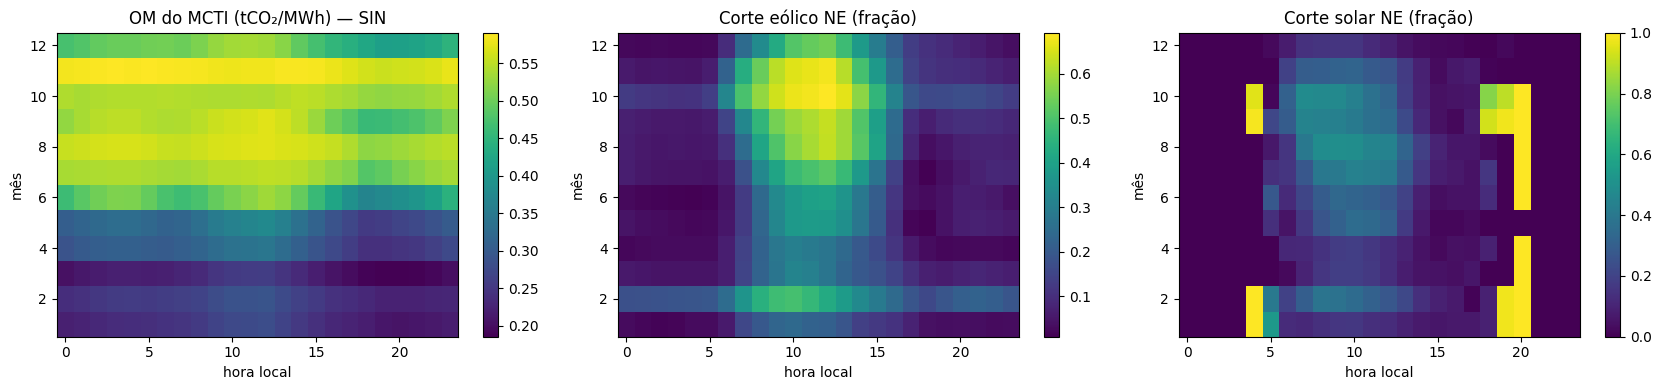

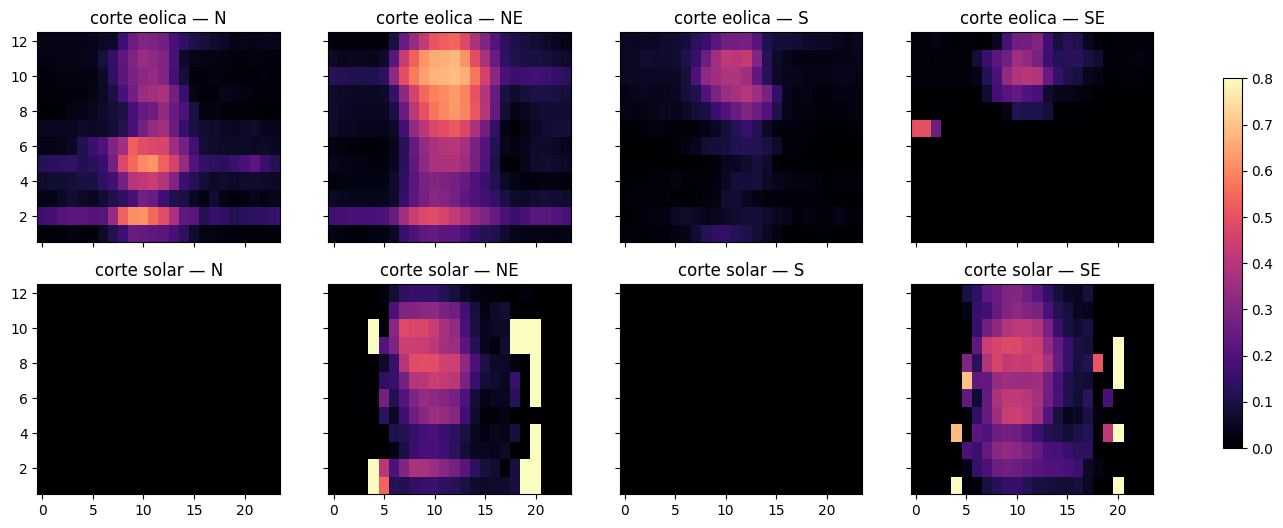

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
om = val[val['subsistema'] == 'SE'].pivot(index='mes', columns='hora_local', values='om')
for a, (titulo, m) in zip(ax, [('OM do MCTI (tCO₂/MWh) — SIN', om),
                               ('Corte eólico NE (fração)', val[val['subsistema'] == 'NE'].pivot(index='mes', columns='hora_local', values='r_eolica')),
                               ('Corte solar NE (fração)', val[val['subsistema'] == 'NE'].pivot(index='mes', columns='hora_local', values='r_solar'))]):
    im = a.imshow(m, aspect='auto', cmap='viridis', origin='lower', extent=[-0.5, 23.5, 0.5, 12.5])
    a.set_title(titulo); a.set_xlabel('hora local'); a.set_ylabel('mês'); fig.colorbar(im, ax=a)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_valor_heatmaps.png', dpi=130); plt.show()

fig, ax = plt.subplots(2, 4, figsize=(18, 6), sharex=True, sharey=True)
for j, s in enumerate(['N', 'NE', 'S', 'SE']):
    for i, f in enumerate(['eolica', 'solar']):
        m = val[val['subsistema'] == s].pivot(index='mes', columns='hora_local', values=f'r_{f}')
        im = ax[i, j].imshow(m, aspect='auto', cmap='magma', vmin=0, vmax=0.8, origin='lower', extent=[-0.5, 23.5, 0.5, 12.5])
        ax[i, j].set_title(f'corte {f} — {s}')
fig.colorbar(im, ax=ax, shrink=0.8); plt.savefig(f'{OUT}/fig_corte_subsistemas.png', dpi=130); plt.show()

## 3. Métricas por célula
- `energia_mwh_por_mw` = Σ dias × CF (MWh por MW instalado no ano)
- `co2_evitado_t_por_mw` = Σ dias × CF × E  ← **métrica principal**
- `intensidade_evitada` = co2/energia (qualidade do horário, independente da quantidade de recurso)
- `perda_por_corte` = fração da energia gerada em horas de corte

In [7]:
# Garante que as colunas geradas na calibração estejam presentes no clima antes de mesclar
if 'cf_eolica' not in clima.columns:
    clima['cf_eolica'] = clima['cf_eolica_bruto'] * ALFA if 'ALFA' in globals() else clima['cf_eolica_bruto']
if 'cf_solar' not in clima.columns:
    clima['cf_solar'] = (clima['cf_solar_bruto'] * FATOR_SOL).clip(0, 1) if 'FATOR_SOL' in globals() else clima['cf_solar_bruto']

base = (clima[['id_celula', 'mes', 'hora_local', 'dias', 'cf_eolica', 'cf_solar']]
        .merge(cel[['id_celula', 'subsistema']], on='id_celula')
        .merge(val, on=['subsistema', 'mes', 'hora_local'], how='left'))
assert base['om'].notna().all(), 'faltou valor para alguma combinação subsistema × mês × hora'

def metricas(f, sufixo=''):
    w = base['dias'] * base[f'cf_{f}']
    g = pd.DataFrame({'id_celula': base['id_celula'], 'w': w, 'wE': w * base[f'E_{f}{sufixo}'],
                      'wr': w * (1 - base[f'r_{f}'])}).groupby('id_celula').sum()
    return g

scores = []
for f in ('eolica', 'solar'):
    g = metricas(f)
    s = pd.DataFrame({'fonte': f, 'cf_anual': g['w'] / 8760, 'energia_mwh_por_mw': g['w'],
                      'co2_evitado_t_por_mw': g['wE'], 'intensidade_evitada': g['wE'] / g['w'],
                      'perda_por_corte': 1 - g['wr'] / g['w']})
    for suf in ('_sem_corte', '_intens_media', '_desp', '_pld', '_corte_ne'):
        s[f'co2{suf}' if suf != '_pld' else 'receita_rs_por_mw'] = metricas(f, suf)['wE']
    scores.append(s)
scores = pd.concat(scores).reset_index().merge(cel[['id_celula', 'lat', 'lon', 'uf', 'municipio', 'subsistema']], on='id_celula')
scores['sem_dado_corte'] = [s in SEM_DADO[f] for f, s in zip(scores['fonte'], scores['subsistema'])]
scores.to_csv(f'{OUT}/scores_celulas.csv', index=False)
print('gravado scores_celulas.csv:', scores.shape)
scores.groupby('fonte')[['cf_anual', 'energia_mwh_por_mw', 'co2_evitado_t_por_mw', 'intensidade_evitada', 'perda_por_corte']].describe(percentiles=[.1, .5, .9]).T.round(3)

gravado scores_celulas.csv: (5684, 18)


fonte                         eolica     solar
cf_anual             count  2842.000  2842.000
                     mean      0.135     0.254
                     std       0.111     0.018
                     min       0.001     0.205
                     10%       0.033     0.233
                     50%       0.101     0.251
                     90%       0.291     0.279
                     max       0.651     0.301
energia_mwh_por_mw   count  2842.000  2842.000
                     mean   1180.703  2223.369
                     std     976.556   157.197
                     min      13.040  1796.897
                     10%     286.329  2036.927
                     50%     887.806  2202.957
                     90%    2548.858  2445.860
                     max    5701.180  2637.395
co2_evitado_t_por_mw count  2842.000  2842.000
                     mean    469.222   841.930
                     std     369.444   106.602
                     min       4.385   585.465
                     10%     106.225   710.320
                     50%     361.266   835.465
                     90%     988.146   980.379
                     max    2005.739  1114.942
intensidade_evitada  count  2842.000  2842.000
                     mean      0.400     0.381
                     std       0.039     0.060
                     min       0.256     0.312
                     10%       0.343     0.319
                     50%       0.407     0.335
                     90%       0.444     0.451
                     max       0.472     0.463
perda_por_corte      count  2842.000  2842.000
                     mean      0.097     0.128
                     std       0.058     0.123
                     min       0.026     0.000
                     10%       0.034     0.000
                     50%       0.105     0.223
                     90%       0.189     0.259
                     max       0.339     0.266

In [8]:
for f in ('eolica', 'solar'):
    print(f'\nTop-20 células — {f} (tCO₂ evitadas por MW por ano)')
    display(scores[scores['fonte'] == f].nlargest(20, 'co2_evitado_t_por_mw')
            [['municipio', 'uf', 'subsistema', 'lat', 'lon', 'cf_anual', 'co2_evitado_t_por_mw', 'intensidade_evitada', 'perda_por_corte', 'sem_dado_corte']].round(3))


Top-20 células — eolica (tCO₂ evitadas por MW por ano)


,municipio,uf,subsistema,lat,lon,cf_anual,co2_evitado_t_por_mw,intensidade_evitada,perda_por_corte,sem_dado_corte
494,Areia Branca,RN,NE,-5.0,-37.0,0.651,2005.739,0.352,0.184,False
189,Barreirinhas,MA,N,-2.5,-43.0,0.556,1945.059,0.399,0.132,False
567,Jardim de Angicos,RN,NE,-5.5,-36.0,0.635,1917.781,0.345,0.210,False
2608,"Área Operacional ""Lagoa dos Patos""",RS,S,-31.5,-51.5,0.556,1887.542,0.388,0.069,False
797,Juazeirinho,PB,NE,-7.0,-36.5,0.605,1856.147,0.350,0.198,False
2615,São José do Norte,RS,S,-32.0,-52.0,0.537,1828.585,0.388,0.068,False
720,Frei Martinho,PB,NE,-6.5,-36.5,0.587,1819.334,0.354,0.195,False
568,Afonso Bezerra,RN,NE,-5.5,-36.5,0.585,1809.856,0.353,0.198,False
2372,Arraial do Cabo,RJ,SE,-23.0,-42.0,0.508,1798.394,0.404,0.038,False
1039,Afrânio,PE,NE,-8.5,-41.0,0.572,1770.019,0.353,0.201,False



Top-20 células — solar (tCO₂ evitadas por MW por ano)


,municipio,uf,subsistema,lat,lon,cf_anual,co2_evitado_t_por_mw,intensidade_evitada,perda_por_corte,sem_dado_corte
3575,Barão de Grajaú,MA,N,-6.5,-43.0,0.285,1114.942,0.446,0.0,True
3031,Barreirinhas,MA,N,-2.5,-43.0,0.283,1111.016,0.449,0.0,True
3576,Sucupira do Riachão,MA,N,-6.5,-43.5,0.284,1108.910,0.446,0.0,True
3088,Araioses,MA,N,-3.0,-42.0,0.281,1107.638,0.450,0.0,True
4042,Alto Parnaíba,MA,N,-9.5,-46.5,0.283,1101.224,0.444,0.0,True
3577,Pastos Bons,MA,N,-6.5,-44.0,0.281,1099.083,0.447,0.0,True
4113,Alto Parnaíba,MA,N,-10.0,-46.0,0.282,1095.864,0.444,0.0,True
3735,Loreto,MA,N,-7.5,-45.5,0.281,1095.518,0.445,0.0,True
4041,Alto Parnaíba,MA,N,-9.5,-46.0,0.281,1095.410,0.445,0.0,True
3655,Benedito Leite,MA,N,-7.0,-44.5,0.280,1093.392,0.446,0.0,True


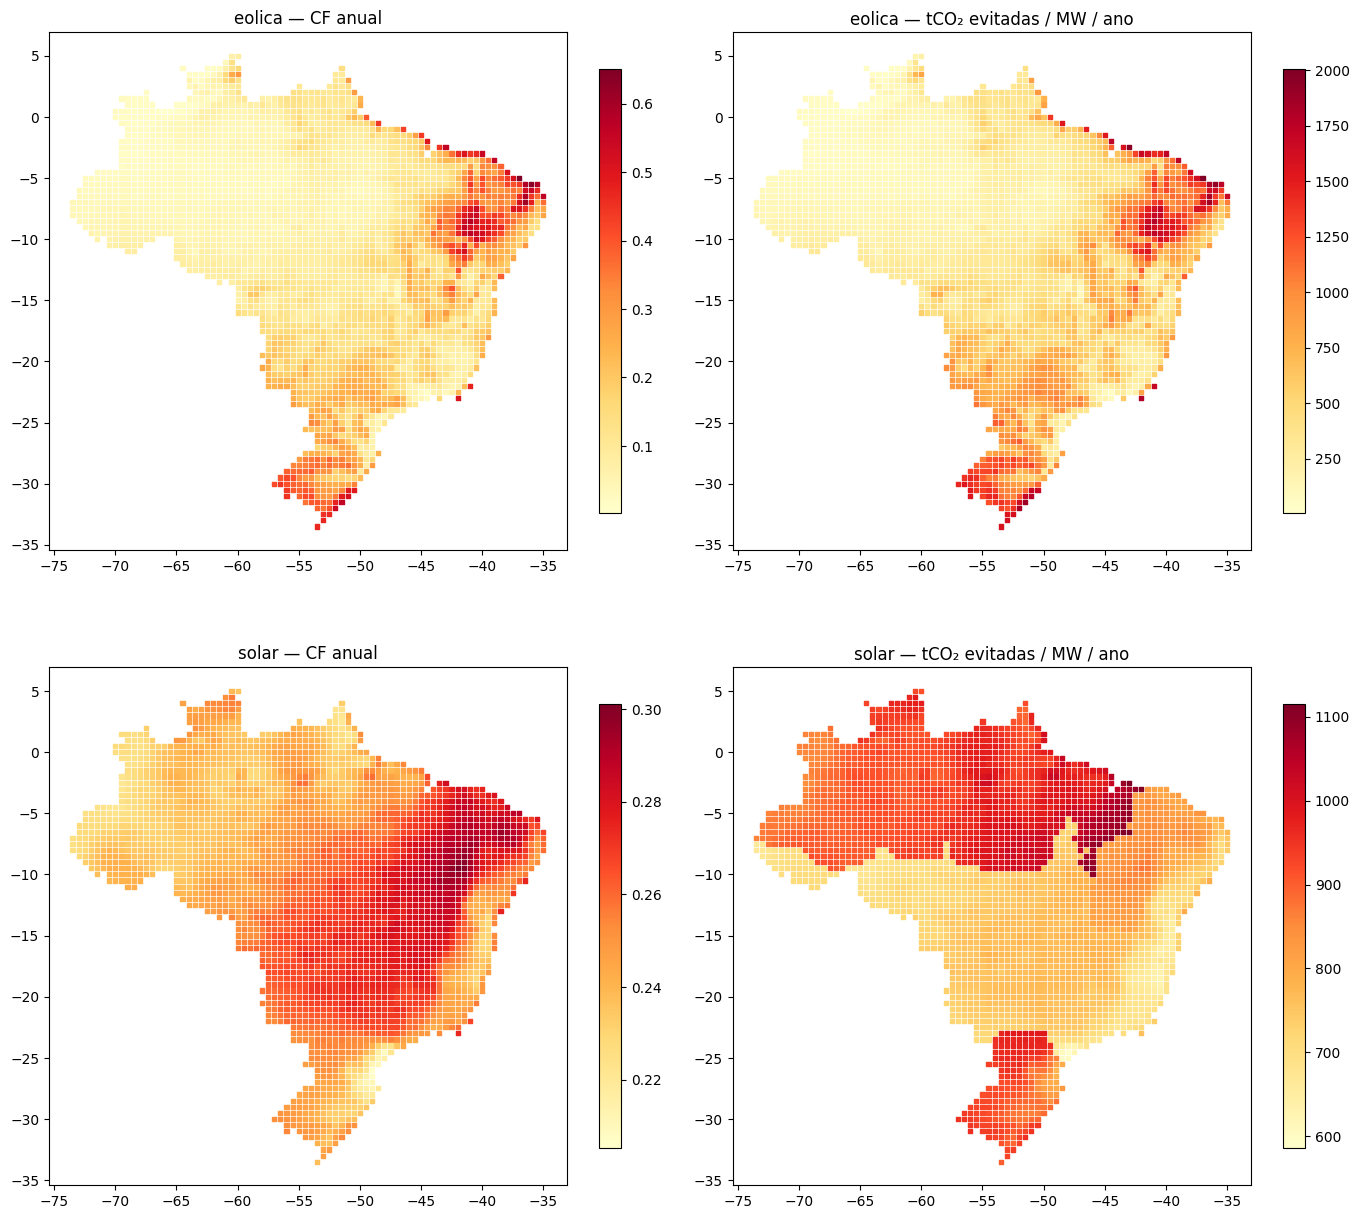

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(14, 13))
for i, f in enumerate(['eolica', 'solar']):
    d = scores[scores['fonte'] == f]
    for j, (col, tit) in enumerate([('cf_anual', 'CF anual'), ('co2_evitado_t_por_mw', 'tCO₂ evitadas / MW / ano')]):
        sc = ax[i, j].scatter(d['lon'], d['lat'], c=d[col], s=9, marker='s', cmap='YlOrRd')
        ax[i, j].set_title(f'{f} — {tit}'); ax[i, j].set_aspect('equal'); fig.colorbar(sc, ax=ax[i, j], shrink=0.7)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_mapas_scores.png', dpi=130); plt.show()

## 4. Clustering (regionalização)
O cluster agrupa células com **regime** parecido (forma do perfil diário e sazonal, nível de recurso, horário e corte); depois os clusters são **ordenados** pela métrica principal — é essa ordenação que responde "onde". Células com recurso irrisório (CF anual abaixo do limiar) ficam fora.

Features: perfil de 24 h e de 12 meses divididos pelo CF anual (forma) → padronizados → PCA (90 % da variância); mais 3 escalares padronizados (CF anual, intensidade evitada, perda por corte), com peso que dá aos dois blocos a mesma variância total.

In [10]:
CF_MIN = {'eolica': 0.15, 'solar': 0.12}   # limiar de recurso (CF anual calibrado)

def features(f):
    ok = scores[(scores['fonte'] == f) & (scores['cf_anual'] >= CF_MIN[f])].set_index('id_celula')
    d = clima[clima['id_celula'].isin(ok.index)]
    p24 = (d.assign(w=d['dias'] * d[f'cf_{f}']).groupby(['id_celula', 'hora_local'])['w'].sum()
           / d.groupby(['id_celula', 'hora_local'])['dias'].sum()).unstack()
    p12 = d.groupby(['id_celula', 'mes'])[f'cf_{f}'].mean().unstack()
    p24 = p24.div(ok['cf_anual'], axis=0).add_prefix('h'); p12 = p12.div(ok['cf_anual'], axis=0).add_prefix('m')
    esc = ok[['cf_anual', 'intensidade_evitada', 'perda_por_corte']]
    return ok, p24.join(p12).loc[ok.index], esc

for f in ('eolica', 'solar'):
    ok, forma, esc = features(f)
    print(f'{f}: {len(ok)} células com CF ≥ {CF_MIN[f]} (de {int((scores.fonte == f).sum())}); features de forma {forma.shape}')

eolica: 928 células com CF ≥ 0.15 (de 2842); features de forma (928, 36)
solar: 2842 células com CF ≥ 0.12 (de 2842); features de forma (2842, 36)


eolica: k = 6 (componentes PCA da forma: 6); concordância KMeans × Ward (ARI) = 0.65
solar: k = 5 (componentes PCA da forma: 6); concordância KMeans × Ward (ARI) = 0.62


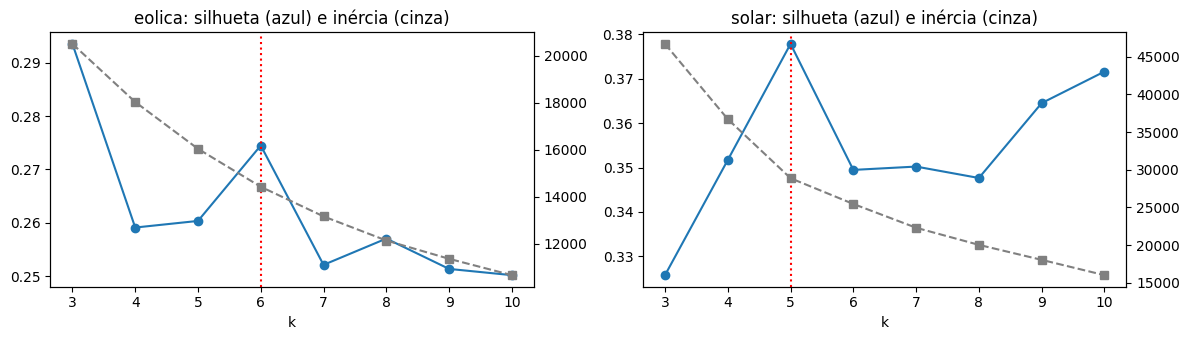

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import kneighbors_graph

K_FORCADO = {'eolica': None, 'solar': None}   # troque por um inteiro para fixar k
res = {}
for f in ('eolica', 'solar'):
    ok, forma, esc = features(f)
    zf = PCA(n_components=0.90, random_state=0).fit_transform(StandardScaler().fit_transform(forma))
    ze = StandardScaler().fit_transform(esc) * np.sqrt(zf.shape[1] / esc.shape[1])
    X = np.hstack([zf, ze])
    sel = []
    for k in range(3, 11):
        km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
        sel.append(dict(k=k, inercia=km.inertia_, silhueta=silhouette_score(X, km.labels_, sample_size=min(3000, len(X)), random_state=0)))
    sel = pd.DataFrame(sel)
    k = K_FORCADO[f] or int(sel[sel['k'].between(4, 8)].sort_values('silhueta', ascending=False)['k'].iloc[0])
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
    conn = kneighbors_graph(ok[['lat', 'lon']].to_numpy(), 8, include_self=False)
    ward = AgglomerativeClustering(n_clusters=k, linkage='ward', connectivity=conn).fit(X)
    res[f] = dict(ok=ok.assign(cluster_km=km.labels_, cluster_ward=ward.labels_), sel=sel, k=k, X=X)
    print(f'{f}: k = {k} (componentes PCA da forma: {zf.shape[1]}); concordância KMeans × Ward (ARI) = {adjusted_rand_score(km.labels_, ward.labels_):.2f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, f in zip(ax, ('eolica', 'solar')):
    s = res[f]['sel']; a.plot(s['k'], s['silhueta'], 'o-'); a2 = a.twinx(); a2.plot(s['k'], s['inercia'], 's--', color='gray')
    a.axvline(res[f]['k'], color='red', ls=':'); a.set_title(f'{f}: silhueta (azul) e inércia (cinza)'); a.set_xlabel('k')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_escolha_k.png', dpi=130); plt.show()

In [12]:
def resumo_clusters(f, col='cluster_km'):
    d = res[f]['ok']
    r = d.groupby(col).agg(celulas=('cf_anual', 'size'),
                           ufs=('uf', lambda s: ', '.join(s.value_counts().index[:4])),
                           cf_anual=('cf_anual', 'median'),
                           co2_mediana=('co2_evitado_t_por_mw', 'median'),
                           co2_p10=('co2_evitado_t_por_mw', lambda s: s.quantile(.1)),
                           co2_p90=('co2_evitado_t_por_mw', lambda s: s.quantile(.9)),
                           intensidade=('intensidade_evitada', 'median'),
                           perda_corte=('perda_por_corte', 'median'))
    r = r.sort_values('co2_mediana', ascending=False)
    r.insert(0, 'rank', range(1, len(r) + 1))
    res[f]['ok']['rank_cluster'] = res[f]['ok'][col].map(r['rank'])
    return r

for f in ('eolica', 'solar'):
    r = resumo_clusters(f)
    r.to_csv(f'{OUT}/resumo_clusters_{f}.csv')
    print(f'\nClusters — {f} (rank 1 = mais tCO₂ evitada por MW)'); display(r.round(3))


Clusters — eolica (rank 1 = mais tCO₂ evitada por MW)


,rank,celulas,ufs,cf_anual,co2_mediana,co2_p10,co2_p90,intensidade,perda_corte
cluster_km,,,,,,,,,
2,1,133,"BA, PE, CE, PB",0.391,1218.268,838.595,1640.303,0.360,0.194
3,2,67,"CE, MA, PI, PE",0.327,1004.821,563.052,1604.172,0.359,0.237
1,3,186,"RS, SP, MG, PR",0.261,934.704,610.291,1445.520,0.406,0.066
5,4,343,"MS, MG, SP, PR",0.200,745.421,601.311,972.748,0.433,0.040
0,5,107,"PI, TO, BA, MA",0.215,732.290,601.338,1092.185,0.376,0.196
4,6,92,"BA, SE, ES, PE",0.220,692.405,528.354,935.328,0.345,0.187



Clusters — solar (rank 1 = mais tCO₂ evitada por MW)


,rank,celulas,ufs,cf_anual,co2_mediana,co2_p10,co2_p90,intensidade,perda_corte
cluster_km,,,,,,,,,
1,1,605,"PA, MA, AP, AM",0.247,976.297,927.163,1050.137,0.450,0.000
0,2,248,"RS, PR, SC, MS",0.246,911.232,724.541,964.725,0.430,0.000
3,3,679,"AM, RR, RO, AC",0.236,901.593,701.787,930.218,0.439,0.000
4,4,647,"BA, MG, PI, CE",0.274,771.045,681.219,840.714,0.328,0.236
2,5,663,"MT, GO, MS, TO",0.267,755.306,723.288,771.821,0.323,0.251


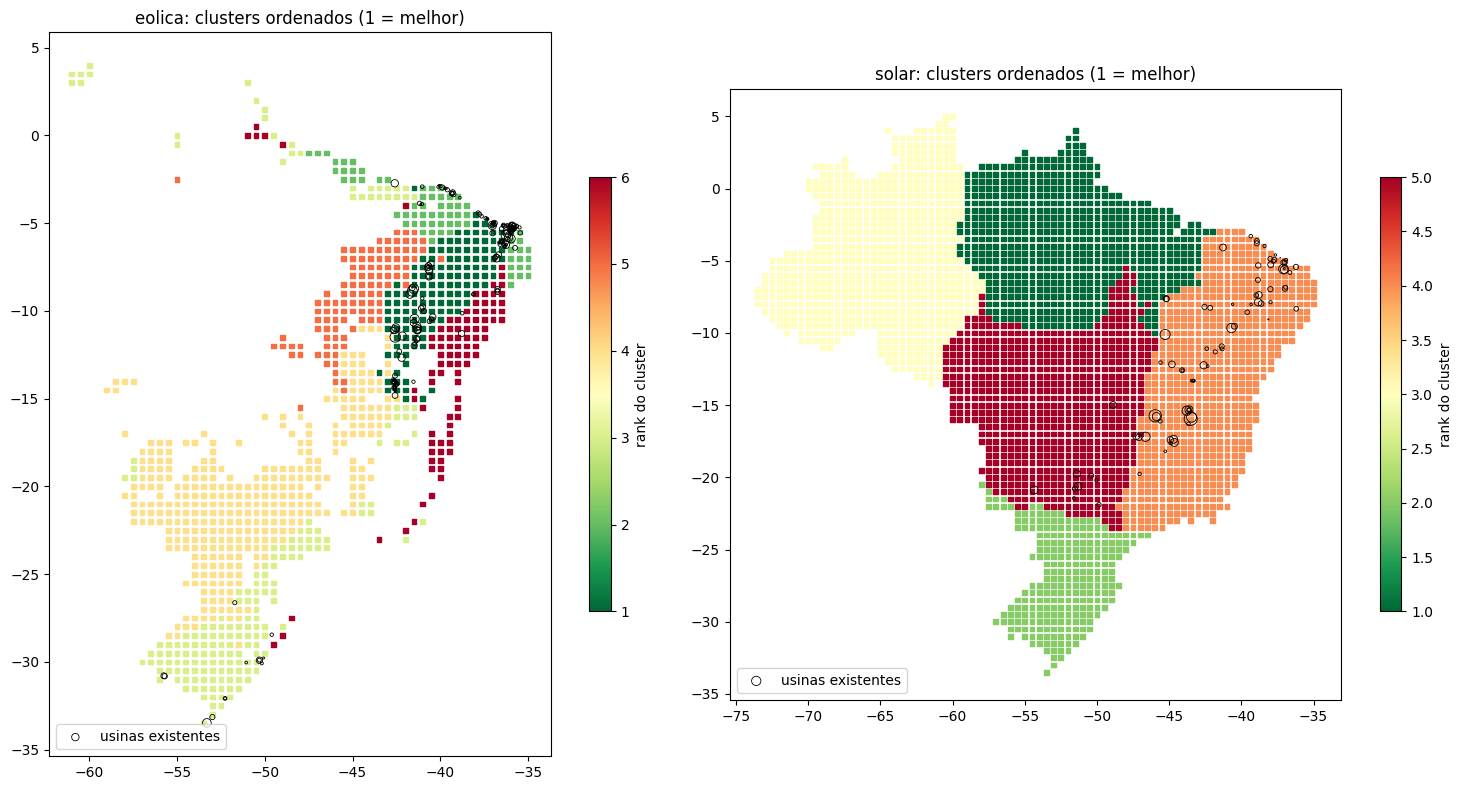

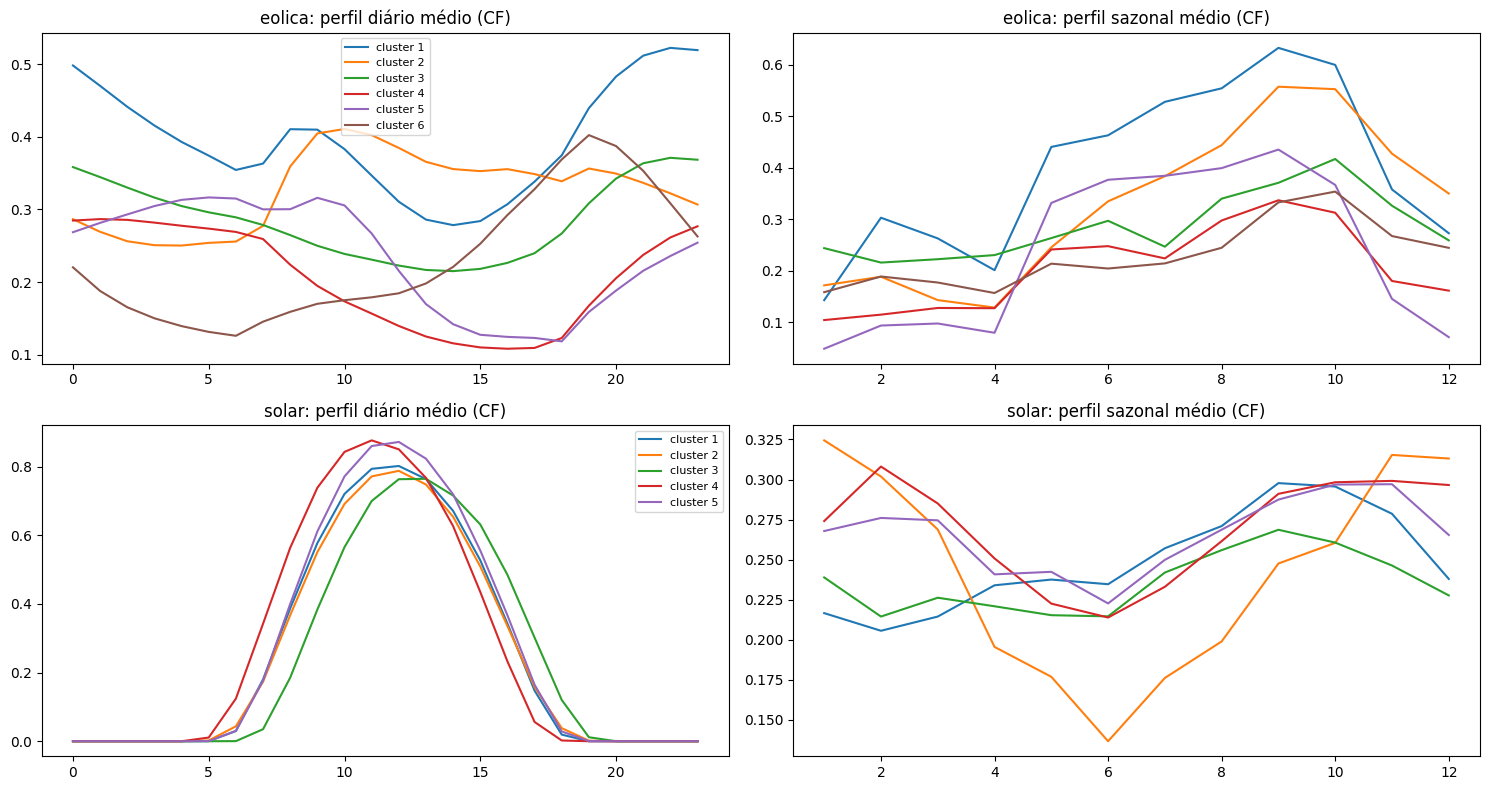


Top-20 eolica com cluster:


,municipio,uf,subsistema,rank_cluster,cf_anual,co2_evitado_t_por_mw,perda_por_corte
id_celula,,,,,,,
cm05.00_m037.00,Areia Branca,RN,NE,1,0.651,2005.739,0.184
cm02.50_m043.00,Barreirinhas,MA,N,2,0.556,1945.059,0.132
cm05.50_m036.00,Jardim de Angicos,RN,NE,1,0.635,1917.781,0.210
cm31.50_m051.50,"Área Operacional ""Lagoa dos Patos""",RS,S,3,0.556,1887.542,0.069
cm07.00_m036.50,Juazeirinho,PB,NE,1,0.605,1856.147,0.198
cm32.00_m052.00,São José do Norte,RS,S,3,0.537,1828.585,0.068
cm06.50_m036.50,Frei Martinho,PB,NE,1,0.587,1819.334,0.195
cm05.50_m036.50,Afonso Bezerra,RN,NE,1,0.585,1809.856,0.198
cm23.00_m042.00,Arraial do Cabo,RJ,SE,3,0.508,1798.394,0.038


Células de alto CF mas fora do top-20 % em CO₂ (muito recurso, pouco valor):
{'BA': 5, 'PB': 5, 'PI': 3, 'CE': 2, 'PE': 1}

Top-20 solar com cluster:


,municipio,uf,subsistema,rank_cluster,cf_anual,co2_evitado_t_por_mw,perda_por_corte
id_celula,,,,,,,
cm06.50_m043.00,Barão de Grajaú,MA,N,1,0.285,1114.942,0.0
cm02.50_m043.00,Barreirinhas,MA,N,1,0.283,1111.016,0.0
cm06.50_m043.50,Sucupira do Riachão,MA,N,1,0.284,1108.910,0.0
cm03.00_m042.00,Araioses,MA,N,1,0.281,1107.638,0.0
cm09.50_m046.50,Alto Parnaíba,MA,N,1,0.283,1101.224,0.0
cm06.50_m044.00,Pastos Bons,MA,N,1,0.281,1099.083,0.0
cm10.00_m046.00,Alto Parnaíba,MA,N,1,0.282,1095.864,0.0
cm07.50_m045.50,Loreto,MA,N,1,0.281,1095.518,0.0
cm09.50_m046.00,Alto Parnaíba,MA,N,1,0.281,1095.410,0.0


Células de alto CF mas fora do top-20 % em CO₂ (muito recurso, pouco valor):
{'BA': 101, 'MG': 92, 'GO': 87, 'PI': 80, 'CE': 47, 'TO': 47, 'PE': 21, 'PB': 13}


In [13]:
ex = usinas.dropna(subset=['lat', 'lon', 'potencia_mw'])
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
for a, f in zip(ax, ('eolica', 'solar')):
    d = res[f]['ok']
    sc = a.scatter(d['lon'], d['lat'], c=d['rank_cluster'], cmap='RdYlGn_r', s=12, marker='s')
    e = ex[ex['grupo'] == f]
    a.scatter(e['lon'], e['lat'], s=e['potencia_mw'] / 15, facecolors='none', edgecolors='k', lw=0.6, label='usinas existentes')
    a.set_aspect('equal'); a.set_title(f'{f}: clusters ordenados (1 = melhor)'); a.legend(loc='lower left')
    fig.colorbar(sc, ax=a, shrink=0.6, label='rank do cluster')
plt.tight_layout(); plt.savefig(f'{OUT}/fig_mapa_clusters.png', dpi=130); plt.show()

fig, ax = plt.subplots(2, 2, figsize=(15, 8))
for i, f in enumerate(('eolica', 'solar')):
    d = res[f]['ok'][['rank_cluster']].join(clima.set_index('id_celula'), how='inner')
    for r, g in d.groupby('rank_cluster'):
        ax[i, 0].plot(g.groupby('hora_local')[f'cf_{f}'].mean(), label=f'cluster {r}')
        ax[i, 1].plot(g.groupby('mes')[f'cf_{f}'].mean(), label=f'cluster {r}')
    ax[i, 0].set_title(f'{f}: perfil diário médio (CF)'); ax[i, 1].set_title(f'{f}: perfil sazonal médio (CF)'); ax[i, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/fig_perfis_clusters.png', dpi=130); plt.show()

for f in ('eolica', 'solar'):
    d = res[f]['ok']
    top = d.nlargest(20, 'co2_evitado_t_por_mw')[['municipio', 'uf', 'subsistema', 'rank_cluster', 'cf_anual', 'co2_evitado_t_por_mw', 'perda_por_corte']]
    top.to_csv(f'{OUT}/top20_{f}.csv'); print(f'\nTop-20 {f} com cluster:'); display(top.round(3))
    print(f'Células de alto CF mas fora do top-20 % em CO₂ (muito recurso, pouco valor):')
    alto_cf = d[d['cf_anual'] >= d['cf_anual'].quantile(.8)]
    print(alto_cf[alto_cf['co2_evitado_t_por_mw'] < d['co2_evitado_t_por_mw'].quantile(.8)].groupby('uf').size().sort_values(ascending=False).head(8).to_dict())

## 5. Sensibilidade — o ranking muda com a definição de valor?
1. sem desconto de corte; 2. intensidade média do subsistema em vez do OM; 3. só a fração fóssil despachada por ordem de mérito; 4. nos subsistemas **sem dado de corte** da fonte (solar no N e no S), aplica a taxa de corte do NE na mesma hora/mês (cenário conservador); 5. valor econômico (PLD × (1 − corte), R$/MW/ano). Medidas: correlação de Spearman com o ranking principal e sobreposição do top-10 %.

In [14]:
alts = {'sem corte': 'co2_sem_corte', 'intensidade média': 'co2_intens_media', 'fóssil despachável': 'co2_desp',
        'corte do NE onde não há dado': 'co2_corte_ne', 'receita PLD': 'receita_rs_por_mw'}
linhas = []
for f in ('eolica', 'solar'):
    d = scores[scores['fonte'] == f]
    top = set(d.nlargest(int(len(d) * .1), 'co2_evitado_t_por_mw')['id_celula'])
    for nome, col in alts.items():
        topa = set(d.nlargest(int(len(d) * .1), col)['id_celula'])
        linhas.append(dict(fonte=f, alternativa=nome, spearman=d['co2_evitado_t_por_mw'].rank().corr(d[col].rank()),
                           sobreposicao_top10=len(top & topa) / len(top)))
sens = pd.DataFrame(linhas); sens.to_csv(f'{OUT}/sensibilidade.csv', index=False)
sens.round(3)

,fonte,alternativa,spearman,sobreposicao_top10
0,eolica,sem corte,0.997,0.877
1,eolica,intensidade média,0.738,0.444
2,eolica,fóssil despachável,0.842,0.613
3,eolica,corte do NE onde não há dado,1.000,1.000
4,eolica,receita PLD,0.997,0.884
5,solar,sem corte,-0.078,0.095
6,solar,intensidade média,0.867,0.870
7,solar,fóssil despachável,0.901,0.743
8,solar,corte do NE onde não há dado,0.229,0.137
9,solar,receita PLD,0.722,0.306


## 6. (Opcional) Deslocamento marginal empírico
Regressão horária das variações da geração fóssil do SIN contra as variações de eólica e solar de cada subsistema, controlando a variação da carga e com efeitos fixos de mês × hora (por demeaning). O coeficiente indica quantos MWh fósseis saem por MWh renovável a mais — indicativo (a hidrelétrica absorve boa parte da variação).

In [15]:
w = ps.pivot_table(index='ts_local', columns='subsistema', values=['ger_eolica_mwh', 'ger_solar_mwh', 'ger_fossil_mwh', 'carga_global_mwh'], aggfunc='sum')
y = w['ger_fossil_mwh'].sum(axis=1).diff()
X = pd.concat({f'{v}_{s}': w[f'ger_{v}_mwh'][s].diff() for v in ('eolica', 'solar') for s in ('N', 'NE', 'S', 'SE')}, axis=1)
X['carga_SIN'] = w['carga_global_mwh'].sum(axis=1).diff()
D = pd.concat([y.rename('y'), X], axis=1).dropna()
grp = [D.index.month, D.index.hour]
D = D - D.groupby(grp).transform('mean')            # efeitos fixos mês × hora
Xm, ym = D.drop(columns='y').to_numpy(), D['y'].to_numpy()
beta, *_ = np.linalg.lstsq(Xm, ym, rcond=None)
resid = ym - Xm @ beta
se = np.sqrt(np.diag(np.linalg.inv(Xm.T @ Xm)) * resid.var(ddof=Xm.shape[1]))
reg = pd.DataFrame({'coef_mwh_fossil_por_mwh': beta, 'erro_padrao': se}, index=D.drop(columns='y').columns)
reg['t'] = reg['coef_mwh_fossil_por_mwh'] / reg['erro_padrao']
reg.to_csv(f'{OUT}/regressao_deslocamento.csv')
reg.round(4)

,coef_mwh_fossil_por_mwh,erro_padrao,t
eolica_N,-0.0615,0.0400,-1.5355
eolica_NE,0.0023,0.0025,0.9310
eolica_S,0.0425,0.0178,2.3965
eolica_SE,0.0045,0.1059,0.0426
solar_N,0.0116,0.0531,0.2183
solar_NE,0.0241,0.0046,5.2107
solar_S,-0.0217,0.0129,-1.6759
solar_SE,0.0094,0.0038,2.4983
carga_SIN,0.0142,0.0016,8.9098


## 7. Síntese

In [16]:
for f in ('eolica', 'solar'):
    r = resumo_clusters(f)
    b = r.iloc[0]
    print(f"{f.upper()}: melhor cluster = UFs {b['ufs']} — {int(b['celulas'])} células, CF mediano {b['cf_anual']:.2f}, "
          f"{b['co2_mediana']:.0f} tCO₂/MW/ano (p10–p90: {b['co2_p10']:.0f}–{b['co2_p90']:.0f}), perda por corte {b['perda_corte']:.0%}")
    s = sens[sens['fonte'] == f].set_index('alternativa')['sobreposicao_top10']
    print('   robustez (sobreposição do top-10 %):', {k: round(v, 2) for k, v in s.items()})
print(f'\nArquivos gravados em {OUT}:', sorted(os.listdir(OUT)))

EOLICA: melhor cluster = UFs BA, PE, CE, PB — 133 células, CF mediano 0.39, 1218 tCO₂/MW/ano (p10–p90: 839–1640), perda por corte 19%
   robustez (sobreposição do top-10 %): {'sem corte': 0.88, 'intensidade média': 0.44, 'fóssil despachável': 0.61, 'corte do NE onde não há dado': 1.0, 'receita PLD': 0.88}
SOLAR: melhor cluster = UFs PA, MA, AP, AM — 605 células, CF mediano 0.25, 976 tCO₂/MW/ano (p10–p90: 927–1050), perda por corte 0%
   robustez (sobreposição do top-10 %): {'sem corte': 0.1, 'intensidade média': 0.87, 'fóssil despachável': 0.74, 'corte do NE onde não há dado': 0.14, 'receita PLD': 0.31}

Arquivos gravados em /content/drive/MyDrive/projeto/resultados_analise_2025: ['fig_corte_subsistemas.png', 'fig_escolha_k.png', 'fig_mapa_clusters.png', 'fig_mapas_scores.png', 'fig_perfis_clusters.png', 'fig_valor_heatmaps.png', 'regressao_deslocamento.csv', 'resumo_clusters_eolica.csv', 'resumo_clusters_solar.csv', 'scores_celulas.csv', 'sensibilidade.csv', 'top20_eolica.csv', 'top20

In [17]:
import os
import pandas as pd
from google.colab import data_table
data_table.enable_dataframe_formatter()          # tabelas viram planilhas interativas (filtrar/ordenar)
D = '/content/extracted_data'

In [18]:
resumo = []
for f in sorted(os.listdir(D)):
    df = pd.read_csv(f'{D}/{f}', nrows=5)
    n = sum(1 for _ in open(f'{D}/{f}')) - 1
    resumo.append(dict(tabela=f.replace('.csv', ''), linhas=n, colunas=df.shape[1],
                       MB=round(os.path.getsize(f'{D}/{f}') / 1e6, 1),
                       algumas_colunas=', '.join(df.columns[:6])))
display(pd.DataFrame(resumo))

,tabela,linhas,colunas,MB,algumas_colunas
0,balanco_subsistema_h,43800,10,4.7,"ts_utc, ts_local, subsistema, ger_hidraulica_m..."
1,capacidade_mensal,907,6,0.0,"uf, subsistema, grupo, potencia_mw, mes, flag_..."
2,carga_h,210240,16,31.0,"area_carga, ts_local, carga_global_mwh, carga_..."
3,clima_agregado_h,451176,8,45.0,"ts_utc, unidade, ws100_ms, ghi_wm2, t2m_c, uni..."
4,clima_perfil_mes_hora,818496,10,99.8,"id_celula, mes, hora_local, n_horas, ws100_ms_..."
5,cmo_h,34944,7,2.2,"submercado, ts_local, cmo_rs_mwh, n_semihoras,..."
6,curva_carga_h,35040,5,2.2,"ts_utc, ts_local, subsistema, carga_mwh, flag_..."
7,cvu_semanal,4844,8,0.3,"mes, dat_iniciosemana, dat_fimsemana, num_revi..."
8,dim_celula,6480,8,0.3,"lat, lon, id_celula, uf, cod_municipio_ibge, m..."
9,dim_tempo,8760,9,0.6,"ts_utc, ts_local, data_local, hora_local, dia_..."


In [19]:
p = pd.read_csv(f'{D}/painel_subsistema_h.csv', parse_dates=['ts_local'])
display(p[p['subsistema'] == 'NE'].head(500))


,ts_utc,subsistema,ger_biomassa_mwh,ger_eolica_mwh,ger_fossil_mwh,ger_hidro_mwh,ger_nuclear_mwh,ger_solar_mwh,emissoes_estimadas_tco2,ger_fossil_sem_fator_mwh,ger_fora_sin_mwh,carga_global_mwh,parcela_mmgd_mwh,regime_metodologico,flag_mmgd_nulo,term_fossil_constrainedoff_mwh,term_fossil_exportacao_mwh,term_fossil_garantiaenergetica_mwh,term_fossil_gfom_mwh,term_fossil_gsub_mwh,term_fossil_inflexibilidade_mwh,term_fossil_ordemmerito_mwh,term_fossil_razaoeletrica_mwh,term_fossil_reposicaoperdas_mwh,term_fossil_reservapotencia_mwh,term_fossil_total_mwh,term_fossil_unitcommitment_mwh,curtail_corte_mwh_eolica,curtail_corte_mwh_solar,ref_eolica_mwh,ref_solar_mwh,intercambio_liquido_mwh,pld_rs_mwh,cmo_rs_mwh,data_local,ear_pct,ena_mwmed,ena_pct_mlt,ws100_ms,ghi_wm2,t2m_c,ws100_ms_pe,ghi_wm2_pe,t2m_c_pe,ws100_ms_ps,ghi_wm2_ps,t2m_c_ps,bal_carga_mwh,bal_ger_hidraulica_mwh,bal_ger_termica_mwh,bal_ger_eolica_mwh,bal_ger_solar_mwh,bal_intercambio_liquido_mwh,intercambio_internacional_mwh,fator_om_mcti_tco2_mwh,carga_liquida_mwh,flag_carga_liquida_sem_mmgd,ts_local
1,2025-01-01 03:00:00+00:00,NE,266.159,16070.653,148.995,2219.280,NaN,0.000,108.115545,NaN,NaN,12167.65950,20.19000,pos_2023_04_mmgd,0,0.0,0.0,0.0,0.0,0.0,3.9965,0.0,0.0000,0.0,0.0,3.9965,0.0,0.0000,0.000,14136.5725,0.0000,-6453.905,58.6,12.200,2025-01-01,50.1757,6223.848,46.1405,5.498685,0.000000,24.522541,7.043756,0.000000,24.714148,6.749799,0.000000,25.941405,12251.182,2219.280,415.154,16070.653,0.000,-6453.905,0.0,0.2582,-3923.18350,0,2025-01-01 00:00:00
5,2025-01-01 04:00:00+00:00,NE,265.613,16353.469,149.037,2199.629,NaN,0.000,108.134963,NaN,NaN,12370.53800,20.19000,pos_2023_04_mmgd,0,0.0,0.0,0.0,0.0,0.0,4.0365,0.0,0.0000,0.0,0.0,4.0365,0.0,0.0000,0.000,14435.5475,0.0000,-6507.586,58.6,10.335,2025-01-01,50.1757,6223.848,46.1405,5.374921,0.000000,24.124174,7.174100,0.000000,24.403680,6.686358,0.000000,25.460690,12460.162,2199.629,414.650,16353.469,0.000,-6507.586,-0.0,0.2507,-4003.12100,0,2025-01-01 01:00:00
9,2025-01-01 05:00:00+00:00,NE,270.360,16971.901,148.495,2198.062,NaN,0.000,107.749482,NaN,NaN,12506.75650,20.19000,pos_2023_04_mmgd,0,0.0,0.0,0.0,0.0,0.0,3.9945,0.0,0.0000,0.0,0.0,3.9945,0.0,0.0000,0.000,15022.8080,0.0000,-7000.190,58.6,10.275,2025-01-01,50.1757,6223.848,46.1405,5.260886,0.000000,23.763920,7.188226,0.000000,23.963369,6.411397,0.000000,24.969032,12588.628,2198.062,418.855,16971.901,0.000,-7000.190,0.0,0.2416,-4485.33450,0,2025-01-01 02:00:00
13,2025-01-01 06:00:00+00:00,NE,268.817,16811.200,147.020,2206.744,NaN,0.000,106.660808,NaN,NaN,12543.69475,20.19000,pos_2023_04_mmgd,0,0.0,0.0,0.0,0.0,0.0,4.0195,0.0,0.0000,0.0,0.0,4.0195,0.0,0.0000,0.000,14806.2965,0.0000,-6829.435,58.6,8.825,2025-01-01,50.1757,6223.848,46.1405,5.127483,0.000000,23.468437,7.197011,0.000000,23.683947,6.142539,0.000000,24.532060,12604.346,2206.744,415.837,16811.200,0.000,-6829.435,-0.0,0.2386,-4287.69525,0,2025-01-01 03:00:00
17,2025-01-01 07:00:00+00:00,NE,272.365,17260.421,147.132,2206.528,NaN,8.244,106.711073,NaN,NaN,12517.08400,20.19000,pos_2023_04_mmgd,0,0.0,0.0,0.0,0.0,0.0,4.1320,0.0,0.0000,0.0,0.0,4.1320,0.0,0.0000,0.000,15377.5660,0.0000,-7298.606,58.6,8.755,2025-01-01,50.1757,6223.848,46.1405,4.967898,0.000000,23.281929,7.154353,0.000000,23.438008,5.866302,0.000000,24.242437,12596.084,2206.528,419.497,17260.421,8.244,-7298.606,0.0,0.2441,-4771.77100,0,2025-01-01 04:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1981,2025-01-21 18:00:00+00:00,NE,294.710,5080.835,119.682,3553.074,NaN,7460.369,86.426545,NaN,NaN,14591.74250,2575.41005,pos_2023_04_mmgd,0,0.0,0.0,0.0,0.0,0.0,4.6815,0.0,0.0000,0.0,0.0,4.6815,0.0,282.3950,0.000,4947.1330,4875.3270,-2512.191,58.6,29.850,2025-01-21,63.7324,17956.898,133.1233,2.379583,466.621857,31.241653,2.799345,462.581114,31.150641,2.404404,459.125289,31.33